# Class balancing and rarity curriculum

Real datasets are imbalanced : some classes have many more examples than others. `acids_dataset` samplers can

- **balance** classes (`balance_by`), such that each class is equally likely (or partially, with `balance_power`) ;
- follow a **curriculum** (`Curriculum`), that samples easy items first, here frequent classes before rare ones
  (`rarity`).

We train a minimal classifier (a linear layer on time-averaged log-mel spectrograms) on an imbalanced synthetic dataset
of 4 classes, with each strategy, and look at what is sampled and at per-class accuracies.

In [1]:
import math, tempfile, collections
from pathlib import Path
import numpy as np
import soundfile as sf
import torch, torch.nn as nn
import torchaudio
import matplotlib.pyplot as plt
from acids_dataset.datasets import AudioDataset
from acids_dataset.sampling import Curriculum, rarity

SR = 16000
torch.manual_seed(0); np.random.seed(0)
root = Path(tempfile.mkdtemp()) / "imbalanced"
root.mkdir()
t = torch.arange(2 * SR) / SR

def harmonic(f0, decay):
    return sum(torch.sin(2 * math.pi * f0 * k * t) * k ** -decay for k in range(1, 30) if f0 * k < SR / 2)

generators = {
    "flute": lambda: harmonic(np.random.uniform(300, 900), decay=3.),             # few partials
    "brass": lambda: harmonic(np.random.uniform(150, 450), decay=0.7),            # bright
    "organ": lambda: harmonic(np.random.uniform(80, 200), decay=1.5) * (1 + 0.3 * torch.sin(2 * math.pi * 6 * t)),
    "snare": lambda: torch.randn(len(t)) * torch.exp(-(t % 0.5) * 20),            # noise bursts
}
counts = {"flute": 24, "brass": 12, "organ": 4, "snare": 2}
for name, n in counts.items():
    for i in range(n):
        x = generators[name]()
        sf.write(root / f"{name}_{i}.wav", (0.3 * x / x.abs().max()).numpy(), SR)

dataset = AudioDataset(root, sr=SR, chunk_length=0.5, meta_regexp=["**/{{instrument}}_*.wav"], output_pattern="{waveform,index}")
labels = dataset.item_labels("instrument")
classes = sorted(counts)
print(len(dataset), "items :", collections.Counter(labels))

168 items : Counter({'flute': 96, 'brass': 48, 'organ': 16, 'snare': 8})


## Comparing sampling strategies

`get_sampler` gives the sampler used by `get_loader`. For each strategy, we count the classes of sampled items at each
epoch (`set_epoch` is called by the training loop, or by Lightning).

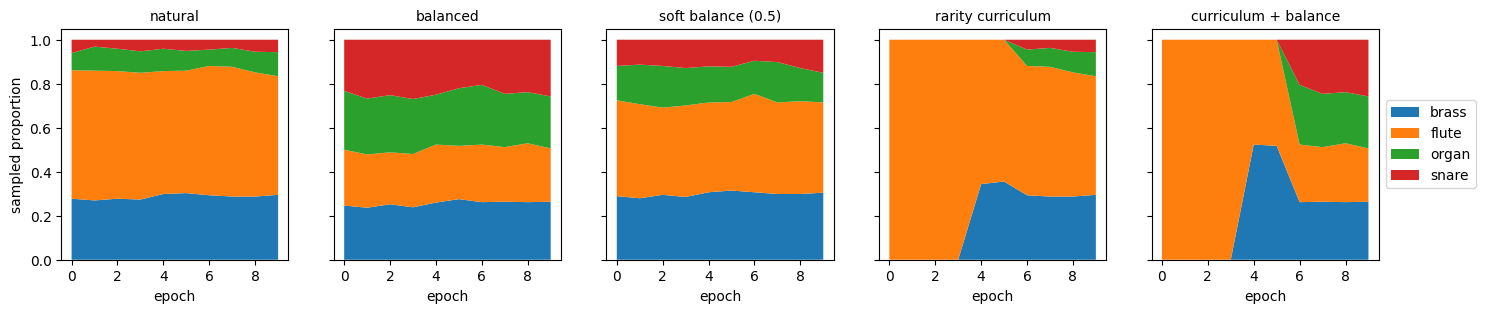

In [2]:
def sampler_for(strategy, max_samples=512):
    if strategy == "natural":
        return dataset.get_sampler(seed=0, max_samples=max_samples)
    if strategy == "balanced":
        return dataset.get_sampler(balance_by="instrument", seed=0, max_samples=max_samples)
    if strategy == "soft balance (0.5)":
        return dataset.get_sampler(balance_by="instrument", balance_power=0.5, seed=0, max_samples=max_samples)
    if strategy == "rarity curriculum":
        curriculum = Curriculum(rarity(labels), start=0.3, end=1., length=6, unit="epoch")
        return dataset.get_sampler(curriculum=curriculum, seed=0, max_samples=max_samples)
    if strategy == "curriculum + balance":
        curriculum = Curriculum(rarity(labels), start=0.3, end=1., length=6, unit="epoch")
        return dataset.get_sampler(balance_by="instrument", curriculum=curriculum, seed=0, max_samples=max_samples)

strategies = ["natural", "balanced", "soft balance (0.5)", "rarity curriculum", "curriculum + balance"]
N_EPOCHS = 10
fig, axes = plt.subplots(1, len(strategies), figsize=(17, 3), sharey=True)
for ax, strategy in zip(axes, strategies):
    sampler = sampler_for(strategy)
    proportions = []
    for epoch in range(N_EPOCHS):
        sampler.set_epoch(epoch)
        c = collections.Counter(labels[i] for i in sampler)
        proportions.append([c[k] / len(sampler) for k in classes])
    ax.stackplot(range(N_EPOCHS), np.array(proportions).T, labels=classes)
    ax.set_title(strategy, fontsize=10); ax.set_xlabel("epoch")
axes[0].set_ylabel("sampled proportion"); axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

The rarity curriculum ranks items by `-log(frequency)` of their class, and samples items whose rank quantile is below
the competence, growing from 0.3 to 1 in 6 epochs. Items with the same difficulty share the same (mean) rank : all
flute items (57 % of the dataset) have a quantile of about 0.29, brass items of about 0.71, ... so classes are
unlocked one by one, when the competence reaches their quantile. Combined with balancing, classes are balanced among
those that are already unlocked. (With `mode="soft"`, weights decrease smoothly above the competence instead.)

## Training a minimal classifier

The model is a linear layer on the time-averaged log-mel spectrogram : 64 x 4 parameters. We train it with each
strategy, with the same number of steps, and evaluate per-class accuracy on fresh chunks.

In [3]:
class TinyClassifier(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.mel = torchaudio.transforms.MelSpectrogram(SR, n_fft=1024, hop_length=256, n_mels=64)
        self.norm = nn.LayerNorm(64)
        self.linear = nn.Linear(64, n_classes)

    def forward(self, x):                                       # (batch, 1, samples)
        features = torch.log(self.mel(x[:, 0]) + 1e-5).mean(-1)  # (batch, 64)
        return self.linear(self.norm(features))

targets = torch.tensor([classes.index(l) for l in labels])

def evaluate(model, n_repeats=4):
    """per-class accuracy over all items (with random chunk positions, repeated)."""
    correct, total = torch.zeros(len(classes)), torch.zeros(len(classes))
    with torch.no_grad():
        for _ in range(n_repeats):
            batch = dataset.get(slice(0, len(dataset)))
            pred = model(batch["waveform"]).argmax(-1)
            y = targets[batch["index"]]
            correct.index_add_(0, y, (pred == y).float()); total.index_add_(0, y, torch.ones_like(y, dtype=torch.float))
    return (correct / total).numpy()

def train(strategy, n_epochs=N_EPOCHS, batch_size=16, max_samples=64, seed=0):
    torch.manual_seed(seed)
    model = TinyClassifier(len(classes))
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    sampler = sampler_for(strategy, max_samples=max_samples)
    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, sampler=sampler)
    history = []
    for epoch in range(n_epochs):
        sampler.set_epoch(epoch)
        for batch in loader:
            loss = nn.functional.cross_entropy(model(batch["waveform"]), targets[batch["index"]])
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        history.append(evaluate(model))
    return np.array(history)                                   # (epochs, classes)

results = {strategy: train(strategy) for strategy in strategies}

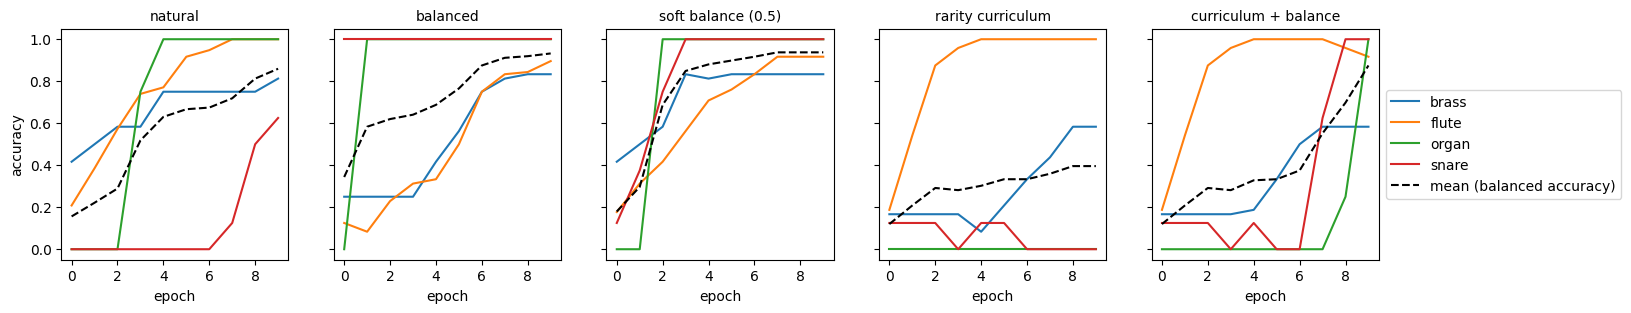

final accuracy           brass   flute   organ   snare      mean
natural                   0.81    1.00    1.00    0.62      0.86
balanced                  0.83    0.90    1.00    1.00      0.93
soft balance (0.5)        0.83    0.92    1.00    1.00      0.94
rarity curriculum         0.58    1.00    0.00    0.00      0.40
curriculum + balance      0.58    0.92    1.00    1.00      0.88


In [4]:
fig, axes = plt.subplots(1, len(strategies), figsize=(17, 3), sharey=True)
for ax, (strategy, history) in zip(axes, results.items()):
    for k, name in enumerate(classes):
        ax.plot(history[:, k], label=name)
    ax.plot(history.mean(-1), "k--", label="mean (balanced accuracy)")
    ax.set_title(strategy, fontsize=10); ax.set_xlabel("epoch")
axes[0].set_ylabel("accuracy"); axes[-1].legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

print("%-22s" % "final accuracy" + "".join("%8s" % c for c in classes) + "%10s" % "mean")
for strategy, history in results.items():
    print("%-22s" % strategy + "".join("%8.2f" % a for a in history[-1]) + "%10.2f" % history[-1].mean())

With natural sampling, the rare snare class is seen only a few times, and is learned last (if at all). Balancing gives
each class the same share of updates, and rare classes are learned from the first epochs. The curriculum first learns
frequent classes alone, and introduces rare classes later : alone, it postpones (or prevents) their learning, as they
remain rare once unlocked ; combined with balancing, they are learned quickly once unlocked. On such a small problem,
curricula mainly show the mechanics ; on real tasks, they are used to stabilize the beginning of training, or to
avoid over-fitting rare (or noisy) examples too early.

## With a data loader

In practice, the same options are given to `get_loader`, that builds the sampler and the `DataLoader` :

In [5]:
curriculum = Curriculum(rarity(labels), start=0.3, end=1., length=6)
loader = dataset.get_loader(batch_size=16, balance_by="instrument", curriculum=curriculum, seed=0, max_samples=128)
for epoch in [0, 3, 6]:
    loader.sampler.set_epoch(epoch)
    seen = collections.Counter(labels[i] for batch in loader for i in batch["index"].tolist())
    print("epoch %d, competence %.2f :" % (epoch, curriculum.competence), dict(seen))

epoch 0, competence 0.30 : {'flute': 128}
epoch 3, competence 0.65 : {'flute': 128}
epoch 6, competence 1.00 : {'brass': 34, 'snare': 27, 'organ': 32, 'flute': 35}
